# Fine-tuning GPT-2: adapting a pretrained causal language model

A pretrained GPT-2 can continue almost any English text, but ask it for **“Recipe: masala dosa”** and it will not reliably give you a recipe in the format your application needs: ingredient list first, then numbered steps, then a clean stop. **Fine-tuning** closes that gap by continuing training on a small set of examples that look like the output you want.

**What you will learn**

1. **What fine-tuning is, and what it is not:** the same next-token objective as pretraining, started from pretrained weights. How it differs from prompting and retrieval.
2. **Data preparation:** turning examples into text, tokens, and *labels*. Which positions give a loss, why `<|endoftext|>` matters, and how to split data without leakage.
3. **The cost of full fine-tuning:** every parameter is updated, so memory is about 4× the weights. We compute it for the GPT-2 family.
4. **The training loop:** learning rate, warmup and decay, gradient clipping, weight decay, and train vs. eval mode.
5. **What can go wrong:** catastrophic forgetting and a model that never stops. Each is reproduced in a small experiment.
6. **Evaluation:** validation loss, fixed-setting generation, base-vs-tuned comparison, and why a falling loss does not prove a better model.

**Scope.** This note covers **full fine-tuning**: every weight is trainable. Parameter-efficient methods (PEFT, LoRA) keep the same loop but train only a small added or selected set of weights. They are covered separately and are deliberately left out here, so that you first see what plain fine-tuning does and costs.

**Prerequisites:** the [GPT-2 notebook](../../../module2/transformers/GPT-2.ipynb) (causal masking, shifted targets, cross-entropy, decoding), tokenization ([BPE notebook](../../../module2/tokenizers/BPE_tokenizer.ipynb)), and basic PyTorch training loops. Related: [key–value cache](../../../module2/transformers/key_value_cache.ipynb) · [GPT-2 lab](../../../module2/labs/gpt2_causal_lm/gpt2_causal_lm_lab.ipynb).

**Setup:** Python 3, PyTorch, matplotlib (`python -m pip install torch matplotlib`). The notebook runs on a CPU in about a minute with a **toy model and a toy dataset**: no downloads. One optional cell in Section 3 also needs `transformers` (`python -m pip install transformers`) and internet, to download the GPT-2 tokenizer (about 2 MB, no model weights). The toy results illustrate mechanisms; they say nothing about real language or real GPT-2 quality.

In [1]:
import copy, itertools, math, random, re
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")   # the toy model needs no GPU; seeds do not guarantee identical GPU results
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.4.0+cu121 | device: cpu


## 1. The idea: continue training on the data you care about

### A concrete problem

We want a model that, given `recipe : dosa ;`, writes the ingredients and steps for a dosa and then stops. Three ways to get there differ in **what they change**:

| Approach | What changes | Needs training? | Typical weakness for GPT-2 |
| --- | --- | --- | --- |
| **Prompting** (instructions or few-shot examples) | the input only | no | GPT-2 was trained only to continue text, not to follow instructions; few-shot formatting is fragile |
| **Retrieval** (put relevant documents in the prompt) | the context, not the weights | no | supplies facts, but does not teach the model an output style or format |
| **Full fine-tuning** | **all weights** | yes | needs data, compute, and care to avoid forgetting |

These are not rivals: a fine-tuned model can still be prompted, and can still be given retrieved context.

### Pretraining vs. fine-tuning

The **objective is identical**: the average negative log-likelihood of each real next token (see the [GPT-2 notebook](../../../module2/transformers/GPT-2.ipynb)).

$$\mathcal{L}(\theta)=-\frac{1}{N}\sum_{t}\log P_\theta\!\left(x_t\mid x_{<t}\right)$$

What differs is everything around it:

| | Pretraining | Fine-tuning |
| --- | --- | --- |
| Initial weights $\theta_0$ | random | **pretrained checkpoint** |
| Data | huge, broad (GPT-2 used the WebText corpus) | small, narrow, chosen for the task |
| Learning rate | large enough to learn from scratch | **small**: we want to *adjust* the weights, not erase them |
| Length of training | very long | minutes to hours: a few epochs |
| Result | general language ability | the same ability, **shifted toward the target distribution** |

Fine-tuning works because the pretrained weights already encode vocabulary, grammar, and a lot of world knowledge. The new data only has to teach what is *specific*: the format, the style, the domain vocabulary, the mapping from a dish to its ingredients.

> **Two ways this can fail.** If we change the weights too little, nothing is learned. If we change them too much, the model gets good at the new data and loses the general ability we started from. This trade-off, **plasticity vs. stability**, runs through the whole note.

### The pipeline

The figure shows the full path from raw examples to a model we can trust. Each box is a section of this note.

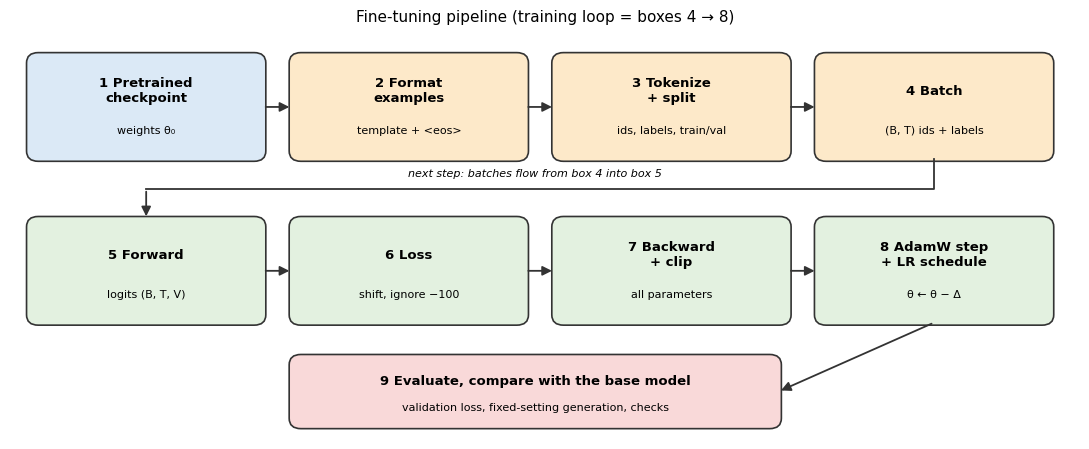

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_pipeline():
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.set_xlim(0, 11); ax.set_ylim(-0.15, 4.6); ax.axis("off")
    def box(x, y, w, h, title, sub, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12", fc=color, ec="#333333", lw=1.2))
        ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=9.5, fontweight="bold")
        ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=8)
    def arrow(p, q):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=14, lw=1.3, color="#333333"))
    row1 = [("1 Pretrained\ncheckpoint", "weights θ₀", "#dbe9f6"),
            ("2 Format\nexamples", "template + <eos>", "#fde9c9"),
            ("3 Tokenize\n+ split", "ids, labels, train/val", "#fde9c9"),
            ("4 Batch", "(B, T) ids + labels", "#fde9c9")]
    row2 = [("5 Forward", "logits (B, T, V)", "#e3f1e0"),
            ("6 Loss", "shift, ignore −100", "#e3f1e0"),
            ("7 Backward\n+ clip", "all parameters", "#e3f1e0"),
            ("8 AdamW step\n+ LR schedule", "θ ← θ − Δ", "#e3f1e0")]
    xs = [0.2, 2.9, 5.6, 8.3]; w, h = 2.4, 1.2
    for (t, s, c), x in zip(row1, xs): box(x, 3.1, w, h, t, s, c)
    for (t, s, c), x in zip(row2, xs): box(x, 1.2, w, h, t, s, c)
    for a, b in zip(xs[:-1], xs[1:]):
        arrow((a + w, 3.7), (b, 3.7)); arrow((a + w, 1.8), (b, 1.8))
    box(2.9, 0.0, 5.0, 0.8, "9 Evaluate, compare with the base model", "validation loss, fixed-setting generation, checks", "#f9d9d9")
    ax.plot([9.5, 9.5, 1.4], [3.1, 2.75, 2.75], color="#333333", lw=1.3)          # wrap from box 4 to box 5
    arrow((1.4, 2.75), (1.4, 2.4))
    arrow((9.5, 1.2), (7.9, 0.4))
    ax.text(5.4, 2.9, "next step: batches flow from box 4 into box 5", ha="center", fontsize=8, style="italic")
    ax.set_title("Fine-tuning pipeline (training loop = boxes 4 → 8)", fontsize=11)
    plt.tight_layout(); plt.show()

draw_pipeline()

**Reading the figure:** the top row prepares data (Sections 3), the bottom row is one training step repeated many times (Sections 5–6), and the last box is how we decide whether anything improved (Section 9). Box 1 is what separates fine-tuning from training from scratch.

## 2. A toy world we can train in seconds

Real GPT-2 has 124 million parameters and needs a GPU for comfortable experiments. To make every mechanism *visible and reproducible on a CPU*, we reproduce the same pattern at small scale:

| Real setting | Toy stand-in |
| --- | --- |
| GPT-2 pretrained on broad web text | a tiny GPT-style model **pretrained** on simple generic sentences (“the cat sat on the mat .”) |
| a task-specific corpus (recipes) | synthetic **recipe records**, e.g. `recipe : dosa ; ingredients : rice , salt , oil ; steps : soak , grind , fry` |
| fine-tuning on recipes | continuing training of the pretrained toy model on recipe records |
| forgetting of general ability | rising loss on the generic sentences |

Design choices that matter for what the toy can teach:

- The pretraining text **already contains** the food words (“the cook chopped the rice .”), so, like real GPT-2, the model knows the *vocabulary* but has never seen the *recipe format* or the dish → ingredient relation.
- Each dish has a pool of 5 ingredients and 4 steps; a recipe uses 3 ingredients and 3 steps in pool order. So there are 40 different recipes per dish, and an **unseen combination** is a fair test of generalization.
- The data is **synthetic and illustrative**. It has no real culinary content, and the toy model is a simplified GPT-2-style network (learned positions, pre-norm blocks, tied embeddings), **not** the Hugging Face GPT-2.

In [3]:
# --- generic "pretraining" sentences ---------------------------------------------------------
ANIMALS = ["cat", "dog", "bird", "fox"]; VERBS = ["sat", "slept", "waited", "ran"]; PLACES = ["mat", "hill", "porch", "bench"]
COOK_VERBS = ["chopped", "mixed", "tasted", "washed"]
# --- recipe domain: dish -> (ingredient pool, step pool) --------------------------------------
POOL = {
    "dosa":  (["rice", "lentil", "salt", "water", "oil"],        ["soak", "grind", "ferment", "fry"]),
    "idli":  (["rice", "lentil", "salt", "water", "ghee"],       ["soak", "grind", "steam", "serve"]),
    "poha":  (["flat_rice", "onion", "peanut", "turmeric", "lime"], ["rinse", "saute", "mix", "serve"]),
    "upma":  (["semolina", "onion", "mustard", "chili", "water"], ["roast", "saute", "stir", "serve"]),
    "raita": (["yogurt", "cucumber", "salt", "cumin", "mint"],   ["chop", "mix", "chill", "serve"]),
    "kheer": (["milk", "rice", "sugar", "cardamom", "raisin"],   ["boil", "stir", "sweeten", "chill"]),
}
ING = sorted({i for ings, _ in POOL.values() for i in ings})

def generic_sentences():
    out = [f"the {a} {v} on the {p} ." for a, v, p in itertools.product(ANIMALS, VERBS, PLACES)]
    out += [f"the cook {c} the {i} ." for c, i in itertools.product(COOK_VERBS, ING)]
    out += [f"the cook made the {d} ; the {d} was good ." for d in POOL]
    out += ["the cook read the recipe .", "the label said : ingredients , steps ."]
    return out

def recipe_records():
    out = []
    for dish, (ings, steps) in POOL.items():
        for ci in itertools.combinations(ings, 3):          # combinations keep pool order
            for cs in itertools.combinations(steps, 3):
                out.append(f"recipe : {dish} ; ingredients : {' , '.join(ci)} ; steps : {' , '.join(cs)}")
    return out

generic, recipes = generic_sentences(), recipe_records()
print(len(generic), "generic sentences |", len(recipes), "distinct recipe records")
print("generic example:", generic[0])
print("recipe  example:", recipes[0])

160 generic sentences | 240 distinct recipe records
generic example: the cat sat on the mat .
recipe  example: recipe : dosa ; ingredients : rice , lentil , salt ; steps : soak , grind , ferment


### Vocabulary, splits, and why we split *first*

Each toy word is one token, with two special tokens: `<pad>` (fills short sequences in a batch) and `<eos>` (end of a document, like GPT-2's `<|endoftext|>`).

**Split before anything is fitted.** We shuffle the recipe records and hold out 40 of them as a **validation** set that is never trained on. Here every record is distinct (we assert it), but in real data you must also watch for **duplicates and near-duplicates** across splits, and for several examples that come from the same source document. If a recipe appears in both train and validation, validation loss measures memory, not generalization. When examples come in groups (the same website, the same author, the same dish family), split by group, not by row.

We also keep a held-out slice of the *generic* sentences. It is not for tuning the recipe model: it measures how much general ability survives fine-tuning.

In [4]:
words = ["<pad>", "<eos>"] + sorted({w for s in generic + recipes for w in s.split()})
stoi = {w: i for i, w in enumerate(words)}
V, PAD, EOS = len(words), 0, 1

def encode(text):                       # one document -> token ids, ending with <eos>
    return [stoi[w] for w in text.split()] + [EOS]
def decode(ids):
    return " ".join(words[i] for i in ids if i != PAD)

rng = random.Random(SEED)
shuffled = recipes[:]; rng.shuffle(shuffled)
rec_train, rec_val = shuffled[:120], shuffled[120:160]           # 120 train / 40 validation records
gen_shuffled = generic[:]; rng.shuffle(gen_shuffled)
gen_train, gen_val = gen_shuffled[:-30], gen_shuffled[-30:]      # held-out generic sentences (forgetting probe)

assert len(set(recipes)) == len(recipes), "duplicate records"
assert not set(rec_train) & set(rec_val), "train/validation overlap"
print("vocabulary size V =", V)
print("encoded example :", encode(rec_train[0])[:12], "...")
print("decoded         :", decode(encode(rec_train[0])))

vocabulary size V = 77
encoded example : [51, 4, 28, 5, 29, 4, 52, 2, 32, 2, 75, 5] ...
decoded         : recipe : idli ; ingredients : rice , lentil , water ; steps : soak , grind , serve <eos>


## 3. Preparing data: from examples to `(input_ids, labels)`

### Formatting

A causal LM only sees a sequence of tokens, so **the task is defined by the text template**. The template should:

- put the *conditioning* part first and the *answer* last (`recipe : dosa ;` → the model completes the rest);
- use markers the model can learn to recognise (`ingredients :`, `steps :`);
- end every document with the end-of-text token, so the model learns **when to stop**.

For real GPT-2 the same example might read `Recipe: Dosa\nIngredients: rice, salt, oil\nSteps: soak, grind, fry<|endoftext|>`.

### Inputs, labels, and the ignored value −100

Training needs two aligned tensors of shape `(B, T)`:

| Tensor | Content |
| --- | --- |
| `input_ids` | the token IDs, right-padded with `<pad>` to the longest sequence in the batch |
| `labels` | the token IDs we want a loss on, and **`-100` wherever there is no loss** |

`-100` is the default `ignore_index` of PyTorch's cross-entropy: those positions contribute nothing to the loss **and are not counted in the average**. Padding must be ignored, because predicting `<pad>` is not a skill we want to teach.

### Shift exactly once

The model's output at position `t` predicts token `t + 1`. So the loss pairs `logits[:, :-1]` with `labels[:, 1:]`. Two conventions exist, and mixing them up is a classic bug:

- **Our toy code (and the GPT-2 notebook):** we shift explicitly, as above.
- **Hugging Face `GPT2LMHeadModel`:** you pass `labels=input_ids` (**unshifted**) and the model shifts internally. Shifting yourself *and* letting the model shift predicts two tokens ahead and trains a quietly wrong model.

The first token of a document is never a prediction target, because nothing precedes it (unless you prepend a start token).

### Loss on every token, or only on the answer?

**The model predicts at every position, including the prompt.**

- In training, the whole record (prompt + answer) goes through the model in **one forward pass**, and `logits` has shape `(B, T, V)`: one next-token distribution **per position**.
- The output at position `t` is the model's guess for token `t + 1`, made from tokens `0 … t` only. The causal mask hides everything after `t`.
- The true previous tokens are fed in rather than the model's own samples (*teacher forcing*). So every guess can be scored at once, prompt positions included.
- Each prompt token therefore plays **two roles**: it is *context* for every later position, and it is the *target* for the position just before it.

For the record `recipe : dosa ; ingredients : rice , salt <eos>`:

| Position `t` | Model has seen | Target (token `t + 1`) | Target is in the… |
| --- | --- | --- | --- |
| 0 | `recipe` | `:` | prompt |
| 1 | `recipe :` | `dosa` | prompt |
| 2 | `recipe : dosa` | `;` | prompt |
| 3 | `… dosa ;` | `ingredients` | prompt |
| 4 | `… ingredients` | `:` | prompt |
| 5 | `… ingredients :` | `rice` | answer |
| 6 | `… rice` | `,` | answer |
| 7 | `… rice ,` | `salt` | answer |
| 8 | `… salt` | `<eos>` | answer |

**Why the prompt seems to have no predictions.** At generation time the model *also* computes logits at every prompt position. We simply discard all of them except the last one, which gives the first answer token. The user supplies the prompt, so there is nothing to predict there. In training the true prompt tokens are known, so scoring those predictions costs almost nothing extra.

**The choice is which of these predictions enter the loss.**

| | Loss on every token | Loss on the answer only |
| --- | --- | --- |
| Labels | `labels = input_ids` (padding still `-100`) | prompt positions also set to `-100` |
| Prompt tokens are… | context **and** targets | context only: still computed, never scored |
| What the model learns | to imitate the prompts too (which dishes appear, how headers look) and to produce the answer | only to produce the answer given the prompt |
| Typical use | adapting to a domain's text; simplest to implement | instruction or chat data, where users write the prompts |
| Watch out for | hard-to-guess prompt tokens (such as the dish name) can dominate the loss | fewer target tokens per example, so less training signal |

**This notebook uses every token.**

The next cell works through the 10-token record above with made-up probabilities, computes the loss both ways, then checks that PyTorch's `ignore_index` gives the same numbers.

In [5]:
tokens = ["recipe", ":", "dosa", ";", "ingredients", ":", "rice", ",", "salt", "<eos>"]
is_completion = [False] * 6 + [True] * 4            # the last 4 tokens are the answer: "rice , salt <eos>"
# Illustrative P(token_t | tokens before it) for t = 1..9. Token 0 has no prefix, so it is never a target.
p = [0.30, 0.02, 0.50, 0.40, 0.60, 0.25, 0.70, 0.20, 0.50]
nll = [-math.log(pi) for pi in p]
print(f"{'target':>12} {'in prompt?':>11} {'P':>6} {'-log P':>8}")
for tok, comp, pi, l in zip(tokens[1:], is_completion[1:], p, nll):
    print(f"{tok:>12} {'no' if comp else 'yes':>11} {pi:6.2f} {l:8.3f}")

loss_all = sum(nll) / len(nll)
loss_completion = sum(l for l, c in zip(nll, is_completion[1:]) if c) / sum(is_completion[1:])
print(f"\nloss over all 9 predictions       = {loss_all:.4f}")
print(f"loss over the 4 completion tokens = {loss_completion:.4f}")

# Same numbers through F.cross_entropy with ignore_index: build logits whose softmax gives exactly P on the target.
Vtoy = 5
logits = torch.zeros(9, Vtoy); targets = torch.zeros(9, dtype=torch.long)       # target is always class 0
for i, pi in enumerate(p):
    logits[i] = torch.log(torch.tensor([pi] + [(1 - pi) / (Vtoy - 1)] * (Vtoy - 1)))
labels_completion_only = targets.clone(); labels_completion_only[:5] = -100       # ignore the 5 prompt targets
print("F.cross_entropy, all           :", round(F.cross_entropy(logits, targets).item(), 4))
print("F.cross_entropy, ignore_index  :", round(F.cross_entropy(logits, labels_completion_only, ignore_index=-100).item(), 4))

      target  in prompt?      P   -log P
           :         yes   0.30    1.204
        dosa         yes   0.02    3.912
           ;         yes   0.50    0.693
 ingredients         yes   0.40    0.916
           :         yes   0.60    0.511
        rice          no   0.25    1.386
           ,          no   0.70    0.357
        salt          no   0.20    1.609
       <eos>          no   0.50    0.693

loss over all 9 predictions       = 1.2535
loss over the 4 completion tokens = 1.0114
F.cross_entropy, all           : 1.2535
F.cross_entropy, ignore_index  : 1.0114


### Batching and padding

A batch is rectangular, so shorter documents are padded on the right. Real GPT-2 has no pad token; the usual practice is to reuse `<|endoftext|>` as padding. That creates the trap in Section 8: the padding positions must be masked **by the attention/padding mask, not by token identity**, or the genuine end-of-text label is erased too.

**Example.** With `pad_token = eos_token`, the ID 50256 (`E`) means two different things in the same row: the real end of the document and the filler after it.

| Position | 0 | 1 | 2 | 3 | 4 | 5 |
| --- | --- | --- | --- | --- | --- | --- |
| `input_ids` | Recipe | : | idli | **E** (real end) | E (pad) | E (pad) |
| `attention_mask` | 1 | 1 | 1 | **1** | 0 | 0 |

- **Mask by token identity** (wrong): `labels[input_ids == pad_token_id] = -100` masks positions 3, 4 and 5. The real end-of-text label is lost, so the model never learns to stop.
- **Mask by attention mask** (correct): `labels[attention_mask == 0] = -100` masks only positions 4 and 5, the filler. Position 3 keeps its label.

Use the attention mask: it records which positions the tokenizer added as padding, which the token IDs alone cannot tell you. (Our toy vocabulary has separate `<pad>` and `<eos>` IDs, so `make_batch` below can safely mask by identity.)

An alternative to padding is **packing**: concatenate many short documents, separated by `<eos>`, into fixed-length blocks. It wastes no compute on padding, but documents can then be split across blocks and, without special attention masking, later documents can attend to earlier unrelated ones.

The function below builds the toy batch.

In [6]:
def make_batch(docs):
    # docs: list of strings -> input_ids and labels, each (B, T), right-padded; pads get label -100
    seqs = [encode(d) for d in docs]
    T = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), T), PAD)
    for r, s in enumerate(seqs):
        ids[r, :len(s)] = torch.tensor(s)
    labels = ids.clone()
    labels[ids == PAD] = -100            # padding is ignored; the real <eos> keeps its label
    return ids, labels

ids, labels = make_batch([generic[0], rec_train[0]])
print("input_ids shape:", tuple(ids.shape), " (B, T)")
for r in range(2):
    print("\nrow", r, "tokens:", decode(ids[r].tolist()).replace("<eos>", "<eos>"))
    print("row", r, "labels:", [("·" if l == -100 else words[l]) for l in labels[r].tolist()])

input_ids shape: (2, 20)  (B, T)

row 0 tokens: the cat sat on the mat . <eos>
row 0 labels: ['the', 'cat', 'sat', 'on', 'the', 'mat', '.', '<eos>', '·', '·', '·', '·', '·', '·', '·', '·', '·', '·', '·', '·']

row 1 tokens: recipe : idli ; ingredients : rice , lentil , water ; steps : soak , grind , serve <eos>
row 1 labels: ['recipe', ':', 'idli', ';', 'ingredients', ':', 'rice', ',', 'lentil', ',', 'water', ';', 'steps', ':', 'soak', ',', 'grind', ',', 'serve', '<eos>']


**Reading the output:** the short generic sentence is padded to the length of the recipe; its pad positions show as `·` (label −100) while its `<eos>` keeps a real label. Every non-pad position, including `<eos>`, gives a loss.

### The same batch with a Hugging Face tokenizer (optional)

With real GPT-2 you do not write `make_batch` yourself. Calling the tokenizer on a **list** of texts tokenizes, pads and converts in one step:

```python
batch = tok(texts, padding=True, truncation=True, max_length=512, return_tensors="pt")
```

It returns a dictionary-like `BatchEncoding`. For GPT-2 it holds exactly two tensors, each `(B, T)`:

| Key | Content |
| --- | --- |
| `input_ids` | subword token IDs, padded to the longest row (`padding=True`) or to `max_length` (`padding="max_length"`) |
| `attention_mask` | `1` for real tokens, `0` for positions the tokenizer added as padding |

BERT's tokenizer also returns `token_type_ids` (segment A or B). GPT-2 has no segments, so its tokenizer does not.

**What the tokenizer does for you:** subword tokenization, padding, the attention mask, truncation (`truncation=True`), and conversion to tensors (`return_tensors="pt"`).

**What it does not do:**

- **Set a pad token.** GPT-2 has none, so `padding=True` raises an error until you set `tok.pad_token = tok.eos_token`.
- **Add `<|endoftext|>`.** GPT-2's tokenizer adds no special tokens, so append `tok.eos_token` to each document yourself.
- **Make labels.** You build them, or a *data collator* does.

The cell below builds a two-recipe batch. It then makes labels in two ways: with the attention-mask rule above, and with Hugging Face's `DataCollatorForLanguageModeling(mlm=False)`, the collator usually paired with causal LMs.

In [ ]:
# Optional: needs the `transformers` library and internet on the first run, to download the GPT-2
# tokenizer files (about 2 MB, no model weights). Nothing later in the notebook uses this cell.
from transformers import AutoTokenizer, DataCollatorForLanguageModeling

tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
print("returns:", tok.model_input_names, "| pad token:", tok.pad_token, "| padding side:", tok.padding_side)
tok.pad_token = tok.eos_token                    # GPT-2 has no pad token: reuse <|endoftext|> (ID 50256)

docs_hf = ["Recipe: idli", "Recipe: masala dosa\nIngredients: rice, urad dal, potato"]
texts = [d + tok.eos_token for d in docs_hf]     # the tokenizer does not add <|endoftext|>; we append it
batch = tok(texts, padding=True, return_tensors="pt")   # pad every row to the longest one
print({k: tuple(v.shape) for k, v in batch.items()}, " (B, T)")
print("row 1 subword tokens:", tok.convert_ids_to_tokens(batch["input_ids"][1]))

# Labels for "loss on every token": copy input_ids, then ignore the positions the tokenizer padded.
labels_hf = batch["input_ids"].clone()
labels_hf[batch["attention_mask"] == 0] = -100

# Hugging Face's collator for causal LMs builds the labels itself, from the token IDs.
collator = DataCollatorForLanguageModeling(tok, mlm=False)
labels_collator = collator([tok(t) for t in texts])["labels"]

row, shown = 0, 7
print(f"\nrow {row}: {texts[row]!r}")
print(f"{'pos':>3} {'token':>15} {'id':>6} {'mask':>5} {'label: mask rule':>17} {'label: collator':>16}")
for t in range(shown):
    print(f"{t:>3} {tok.convert_ids_to_tokens(int(batch['input_ids'][row, t])):>15} {int(batch['input_ids'][row, t]):>6} "
          f"{int(batch['attention_mask'][row, t]):>5} {int(labels_hf[row, t]):>17} {int(labels_collator[row, t]):>16}")
print(f"... {batch['input_ids'].shape[1] - shown} more padding positions, all mask 0 and label -100")

end = int(batch["attention_mask"][row].sum()) - 1     # position of the real <|endoftext|>
assert labels_hf[row, end] == tok.eos_token_id         # the attention-mask rule keeps the stop label
print(f"\nreal <|endoftext|> at position {end}: label {int(labels_hf[row, end])} with the mask rule, "
      f"{int(labels_collator[row, end])} with the collator")

returns: ['input_ids', 'attention_mask'] | pad token: None | padding side: right
{'input_ids': (2, 18), 'attention_mask': (2, 18)}  (B, T)
row 1 subword tokens: ['Recipe', ':', 'Ġmas', 'ala', 'Ġd', 'osa', 'Ċ', 'Ingredients', ':', 'Ġrice', ',', 'Ġur', 'ad', 'Ġd', 'al', ',', 'Ġpotato', '<|endoftext|>']

row 0: 'Recipe: idli<|endoftext|>'
pos           token     id  mask  label: mask rule  label: collator
  0          Recipe  37523     1             37523            37523
  1               :     25     1                25               25
  2             Ġid   4686     1              4686             4686
  3              li   4528     1              4528             4528
  4   <|endoftext|>  50256     1             50256             -100
  5   <|endoftext|>  50256     0              -100             -100
  6   <|endoftext|>  50256     0              -100             -100
... 11 more padding positions, all mask 0 and label -100

real <|endoftext|> at position 4: label 50256 with the mask 

**Reading the output**

- **Two keys, not three.** `input_ids` and `attention_mask`, both `(2, 18)`. Row 0 has 5 real tokens and 13 pads, all with ID 50256.
- **Subwords.** `Ġ` marks a token that starts with a space, and `Ċ` is the newline. `idli` becomes `Ġid` + `li`. The model sees subwords, not words.
- **The same ID, two meanings.** Position 4 (the real end) and positions 5–17 (padding) all hold 50256. Only `attention_mask` tells them apart, so the mask rule keeps label 50256 at position 4.
- **The collator erases the stop label.** It sets `labels = -100` wherever `input_ids == pad_token_id` (checked with `transformers` 4.43), so with `pad_token = eos_token` the real `<|endoftext|>` loses its label. This is the token-identity mistake from the table above, built into a library default. Section 8 shows the result: a model that never stops.
  - **Fix:** build the labels from `attention_mask` yourself, as in the cell, and pass them in the batch.
  - **Or:** give the tokenizer a separate pad token, then resize the model's embeddings with `model.resize_token_embeddings(len(tok))`.
- **What `attention_mask` does inside the model.** The model also uses it to stop real tokens from attending to padded key positions.
  - With **right** padding the pads come after every real token, so the causal mask already hides them. The attention mask changes nothing for the real tokens, and the `-100` labels remove the pads from the loss.
  - It matters for **left** padding, which batched generation uses (`tok.padding_side = "left"`), so that every prompt ends at the last position.

## 4. What “full” fine-tuning costs

In full fine-tuning **every parameter receives a gradient and is updated**. Real GPT-2 small has 124M parameters, and about 32% of them are in the embedding tables (the token table is shared with the output layer). They are updated too.

During training, each parameter needs more than its own value:

| Stored per parameter | Why | fp32 bytes |
| --- | --- | --- |
| Weight $\theta$ | the model | 4 |
| Gradient $\nabla\mathcal{L}$ | backward pass output | 4 |
| Adam first moment $m$ | running mean of gradients | 4 |
| Adam second moment $v$ | running mean of squared gradients | 4 |
| **Total** | | **16 bytes ≈ 4× the weights** |

On top of this come **activations** (the intermediate tensors kept for backpropagation), which grow with batch size and sequence length and are *not* included below. Mixed-precision training keeps an fp32 master copy of the weights, so it saves activation memory more than parameter-state memory. The numbers below are rough planning estimates, not measurements.

The parameter formula comes from the [GPT-2 notebook](../../../module2/transformers/GPT-2.ipynb): $VD + TD + N(12D^2 + 13D) + 2D$ with a tied output head.

  model    params   weights   +grads    +Adam   (GiB, fp32, activations excluded)
  small    124.4M      0.46     0.93     1.85
 medium    354.8M      1.32     2.64     5.29
  large    774.0M      2.88     5.77    11.53
     xl   1557.6M      5.80    11.61    23.21


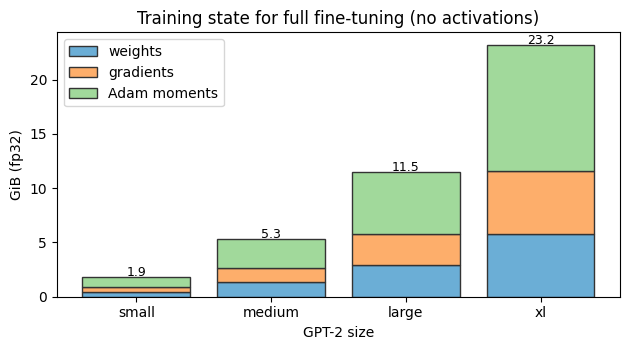

In [7]:
GPT2_SIZES = {          # (layers N, width D) for the original GPT-2 family; V = 50,257 and T = 1,024 for all
    "small":  (12, 768),
    "medium": (24, 1024),
    "large":  (36, 1280),
    "xl":     (48, 1600),
}
def gpt2_param_count(vocab_size, context_size, d_model, n_layers):
    return vocab_size * d_model + context_size * d_model + n_layers * (12 * d_model**2 + 13 * d_model) + 2 * d_model

GIB = 1024**3
print(f"{'model':>7} {'params':>9} {'weights':>9} {'+grads':>8} {'+Adam':>8}   (GiB, fp32, activations excluded)")
sizes, parts = [], {"weights": [], "gradients": [], "Adam moments": []}
for name, (n, d) in GPT2_SIZES.items():
    P = gpt2_param_count(50257, 1024, d, n)
    w, g, a = 4 * P / GIB, 4 * P / GIB, 8 * P / GIB
    sizes.append(name); parts["weights"].append(w); parts["gradients"].append(g); parts["Adam moments"].append(a)
    print(f"{name:>7} {P/1e6:8.1f}M {w:9.2f} {w+g:8.2f} {w+g+a:8.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
bottom = [0] * len(sizes)
for (label, vals), color in zip(parts.items(), ("#6baed6", "#fdae6b", "#a1d99b")):
    ax.bar(sizes, vals, bottom=bottom, label=label, color=color, edgecolor="#333333")
    bottom = [b + v for b, v in zip(bottom, vals)]
for i, tot in enumerate(bottom): ax.text(i, tot + 0.1, f"{tot:.1f}", ha="center", fontsize=9)
ax.set_ylabel("GiB (fp32)"); ax.set_xlabel("GPT-2 size"); ax.set_title("Training state for full fine-tuning (no activations)")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the output**

- GPT-2 small needs about 1.9 GiB of training state before activations, which a laptop CPU or a free GPU handles; GPT-2 XL (1.5B) needs about 23 GiB, which does not fit on a typical free-tier GPU.
- Memory grows linearly with parameter count. Models in the billions of parameters make full fine-tuning expensive, and that is the motivation for the parameter-efficient methods covered separately.
- The estimate says nothing about **time**: the compute per step also scales with parameters, batch size, and sequence length.

## 5. The training loop and its knobs

One training step has five parts: forward, loss, backward, clip, update. The loop is the same as in the GPT-2 notebook; fine-tuning only adds a few decisions about *how gently* to update.

### The toy model

This is the same design as the GPT-2 notebook's model, written compactly: learned token and position embeddings, pre-norm blocks with fused-QKV causal attention (via PyTorch's `scaled_dot_product_attention(is_causal=True)`), a GELU feed-forward network, and a tied output head. With `D = 64`, 4 heads, and 2 blocks it has about 100K parameters, versus 124M for GPT-2 small. It uses dropout (0.1), so `train()` and `eval()` behave differently.

In [8]:
class Block(nn.Module):
    def __init__(self, d, h, p_drop=0.1):
        super().__init__()
        self.h = h
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)               # fused Q,K,V: D -> 3D
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(p_drop)

    def forward(self, x):                                                          # x: (B, T, D)
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(D, dim=-1)
        q, k, v = (t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in (q, k, v))   # (B, H, T, d_k)
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True)                # causal mask inside
        x = x + self.drop(self.proj(a.transpose(1, 2).reshape(B, T, D)))
        return x + self.drop(self.ff(self.ln2(x)))

class TinyLM(nn.Module):
    def __init__(self, vocab, d=64, heads=4, layers=2, ctx=48):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(ctx, d)
        self.blocks = nn.ModuleList(Block(d, heads) for _ in range(layers))
        self.lnf = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab, bias=False); self.head.weight = self.tok.weight   # weight tying
        self.ctx = ctx
        for m in self.modules():                                                    # GPT-2 style init
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0, 0.02)
                if getattr(m, "bias", None) is not None: nn.init.zeros_(m.bias)
        for b in self.blocks:                                                       # scale residual projections
            nn.init.normal_(b.proj.weight, 0, 0.02 / math.sqrt(2 * layers))
            nn.init.normal_(b.ff[2].weight, 0, 0.02 / math.sqrt(2 * layers))
            
    def forward(self, ids):                                                         # ids: (B, T) -> logits (B, T, V)
        x = self.tok(ids) + self.pos(torch.arange(ids.size(1)))
        for b in self.blocks: x = b(x)
        return self.head(self.lnf(x))

def lm_loss(model, ids, labels):
    # shift once: logits at t predict the label at t+1; -100 positions are ignored and not counted
    logits = model(ids)
    return F.cross_entropy(logits[:, :-1].reshape(-1, V), labels[:, 1:].reshape(-1), ignore_index=-100)

@torch.no_grad()
def evaluate(model, docs):
    model.eval()                                    # dropout off for evaluation
    loss = lm_loss(model, *make_batch(docs)).item()
    model.train()
    return loss

torch.manual_seed(SEED)
tiny = TinyLM(V)
print("parameters:", sum(p.numel() for p in tiny.parameters()))
print("untrained loss on recipes:", round(evaluate(tiny, rec_val), 3), "| ln V =", round(math.log(V), 3))

parameters: 108096
untrained loss on recipes: 4.355 | ln V = 4.344


The untrained model gives a loss near $\ln V$ (every token about equally likely), the same sanity check as in the GPT-2 notebook. Starting far above it would suggest a bad initialization or a bug.

Because an untrained model's predictions are close to uniform. If every one of the $V$ tokens gets probability about $1/V$, the loss on each position is

$$-\log P(\text{correct token}) \approx -\ln\frac{1}{V} = \ln V$$

Averaging over positions gives the same value, $\ln V$.

### The knobs

| Knob | What it controls | Typical practice and reasoning |
| --- | --- | --- |
| **Learning rate** (peak) | size of each weight update | The most important choice. For full fine-tuning it is normally **much smaller than the pretraining rate**. Hugging Face `Trainer` defaults to `5e-5`; treat that only as a starting point and choose by validation loss |
| **Warmup** | LR rises linearly from 0 over the first few percent of steps | Adam's moment estimates are noisy at the start; a short warmup avoids a destructive first few updates |
| **Decay** | LR falls (linearly or cosine) to ~0 | large steps early to adapt, small steps late to settle |
| **Gradient clipping** | rescales the gradient if its norm exceeds a limit (commonly 1.0) | protects against a rare spike from one odd batch |
| **Weight decay** (AdamW) | shrinks weights slightly each step, *decoupled* from the gradient | mild regularization; often not applied to biases and layer-norm parameters |
| **Batch size** | examples per update | larger = smoother gradient, more memory |
| **Gradient accumulation** | sum gradients over several micro-batches before one update | simulates a larger batch when memory is limited |
| **Epochs / steps** | how many passes over the data | few epochs; stop by validation loss, not by training loss |
| **train() vs. eval()** | dropout on or off | `train()` for updates, `eval()` for measurement and generation |

### Learning-rate schedule

With peak learning rate $\eta_{\max}$, total steps $S$, and warmup steps $S_w$:

$$\eta(s)=\begin{cases}\eta_{\max}\,\dfrac{s+1}{S_w} & s<S_w\\[2mm] \eta_{\max}\,\dfrac{S-s}{S-S_w} & s\ge S_w\end{cases}$$

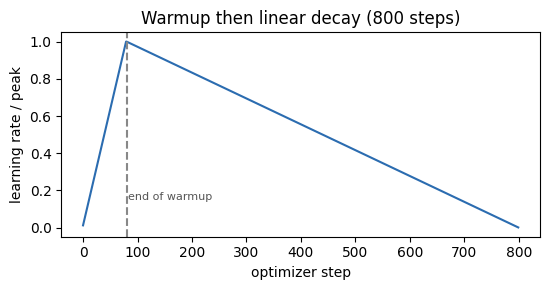

In [9]:
def lr_factor(step, total, warmup_frac=0.1):
    # multiplier on the peak learning rate: linear warmup, then linear decay to 0
    warm = max(1, int(warmup_frac * total))
    return (step + 1) / warm if step < warm else (total - step) / (total - warm)

total = 800
steps = list(range(total))
fig, ax = plt.subplots(figsize=(5.6, 3.0))
ax.plot(steps, [lr_factor(s, total) for s in steps], color="#2b6cb0")
ax.axvline(int(0.1 * total), ls="--", color="#888888"); ax.text(int(0.1 * total) + 2, 0.15, "end of warmup", fontsize=8, color="#555555")
ax.set_xlabel("optimizer step"); ax.set_ylabel("learning rate / peak"); ax.set_title("Warmup then linear decay (800 steps)")
plt.tight_layout(); plt.show()

### The training function

The function below is the loop of boxes 4–8 in the pipeline figure. It evaluates on several held-out sets every few steps so that we can watch both the **target** domain (recipes) and the **original** domain (generic sentences).

In [10]:
def finetune(model, docs, steps, lr, batch_size=16, warmup_frac=0.1, eval_sets=None, eval_every=10,
             weight_decay=0.01, clip=1.0, seed=0, make=make_batch):
    # Full fine-tuning: every parameter is trainable. Returns a history of (step, train_loss, {name: eval_loss}).
    g = torch.Generator().manual_seed(seed)                               # controls batch order only
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: lr_factor(s, steps, warmup_frac))
    history = [(0, float("nan"), {k: evaluate(model, v) for k, v in (eval_sets or {}).items()})]
    model.train()
    for step in range(steps):
        batch = [docs[i] for i in torch.randint(0, len(docs), (batch_size,), generator=g).tolist()]
        loss = lm_loss(model, *make(batch))
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)         # rescale if the gradient norm exceeds `clip`
        opt.step()
        sched.step()
        if (step + 1) % eval_every == 0 or step == steps - 1:
            history.append((step + 1, loss.item(), {k: evaluate(model, v) for k, v in (eval_sets or {}).items()}))
    return history

## 6. Pretrain, then fine-tune

### Step 1: a small “pretrained” model

We first train the toy model on the **generic** sentences only. This plays the role of GPT-2's pretraining: broad text, high learning rate, many steps. Afterwards it should know the generic sentences well and be poor at recipes.

In [11]:
FT_STEPS = 800            # fine-tuning length used in Sections 6-9 (the toy model needs a few hundred steps)
eval_sets = {"recipes (val)": rec_val, "generic (held out)": gen_val}
torch.manual_seed(SEED)
base = TinyLM(V)
pre_hist = finetune(base, gen_train, steps=400, lr=3e-3, eval_sets=eval_sets, eval_every=20)   # "pretraining": same loop, large LR
base.eval()
for k, v in pre_hist[-1][2].items(): print(f"base model loss on {k:20}: {v:.3f}")

base model loss on recipes (val)       : 4.477
base model loss on generic (held out)  : 1.088


- The base model's loss on generic sentences is low but not zero: those sentences are random combinations, so some uncertainty is irreducible.
- Its loss on recipes is high. It knows the words but not the format or the dish → ingredient relation. This is the gap fine-tuning has to close.

### Step 2: fine-tune on recipe records

We copy the pretrained weights (`copy.deepcopy`) so that the same starting point can be reused for every experiment, then train all parameters on the 120 training recipes with a **much smaller learning rate** (`1e-3` here, versus `3e-3` for pretraining).

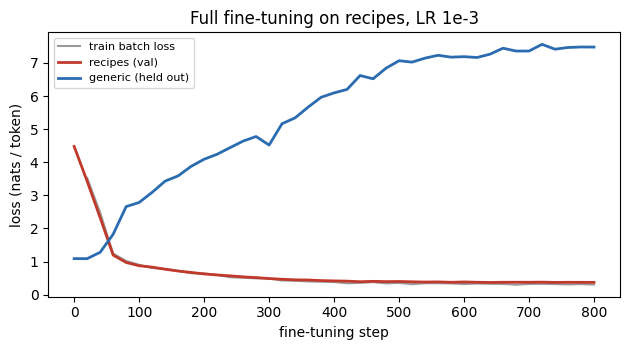

recipes (val):       4.477 -> 0.371
generic (held out):  1.088 -> 7.478


In [12]:
ft = copy.deepcopy(base)
ft_hist = finetune(ft, rec_train, steps=FT_STEPS, lr=1e-3, eval_sets=eval_sets, eval_every=20)

def plot_history(hist, title, ax=None):
    s = [h[0] for h in hist]
    ax.plot([h[0] for h in hist[1:]], [h[1] for h in hist[1:]], color="#999999", label="train batch loss")
    for (name, color) in (("recipes (val)", "#c0392b"), ("generic (held out)", "#2b6cb0")):
        ax.plot(s, [h[2][name] for h in hist], color=color, lw=2, label=name)
    ax.set_xlabel("fine-tuning step"); ax.set_ylabel("loss (nats / token)"); ax.set_title(title); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
plot_history(ft_hist, "Full fine-tuning on recipes, LR 1e-3", ax)
plt.tight_layout(); plt.show()
print("recipes (val):      ", round(ft_hist[0][2]["recipes (val)"], 3), "->", round(ft_hist[-1][2]["recipes (val)"], 3))
print("generic (held out): ", round(ft_hist[0][2]["generic (held out)"], 3), "->", round(ft_hist[-1][2]["generic (held out)"], 3))

**Reading the figure**

- **Red (recipe validation loss)** drops steeply, from about 4.5 to well under 1. The model learned the format and much of the dish-specific content, and the loss is low on recipe records it never trained on. Section 9 looks at what it actually writes.
- **Blue (generic held-out loss)** goes **up**. We never trained on generic sentences again, so improving at recipes cost some of the original ability. This is **catastrophic forgetting**: the updates that serve the new data move weights that the old data relied on. In this tiny model it is stronger than it would be for GPT-2, but the direction is the same.

### Qualitative check: same prompt, same decoding, before and after

Numbers like loss are necessary but not sufficient. We generate from the same prompts with the same settings (greedy decoding: always the most probable token, so there is no randomness) for the base and the fine-tuned model.

In [13]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=30, temperature=None, generator=None):
    # greedy if temperature is None, otherwise sample from softmax(logits / temperature); stops at <eos>
    model.eval()
    ids = torch.tensor([encode(prompt)[:-1]])                        # drop the <eos> that encode() appends
    for _ in range(max_new_tokens):
        logits = model(ids[:, -model.ctx:])[0, -1]
        nxt = logits.argmax() if temperature is None else torch.multinomial((logits / temperature).softmax(-1), 1, generator=generator)[0]
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)
        if nxt.item() == EOS: break
    model.train()
    return decode(ids[0].tolist())

for prompt in ["recipe : dosa ;", "recipe : kheer ;", "the cat sat"]:
    print("prompt     :", prompt)
    print("  base     :", generate(base, prompt))
    print("  fine-tuned:", generate(ft, prompt), "\n")

prompt     : recipe : dosa ;
  base     : recipe : dosa ; ingredients , , , , , . <eos>
  fine-tuned: recipe : dosa ; ingredients : rice , lentil , water ; steps : soak , grind , fry <eos> 

prompt     : recipe : kheer ;
  base     : recipe : kheer ; ingredients , , , , , . <eos>
  fine-tuned: recipe : kheer ; ingredients : milk , sugar , cardamom ; steps : boil , stir , sweeten <eos> 

prompt     : the cat sat
  base     : the cat sat on the mat . <eos>
  fine-tuned: the cat sat : rice , chili , water , ghee ; steps : roast , saute , serve <eos> 



**Reading the output**

- The base model does not produce the recipe format for the recipe prompts. The fine-tuned model writes the full format, with content that fits each dish, and ends with `<eos>`.
- On the generic prompt the base model completes the sentence, while the fine-tuned model drifts into recipe vocabulary (`the cat sat : rice , chili , ...`). That is forgetting seen in the text, not only in the loss.
- Two greedy examples cannot tell us how often the content is right. Fluent, correctly formatted output can still contain **wrong content**, such as a step that does not belong to that dish. Section 9 measures this over many samples instead of eyeballing a few.

## 7. How hard to push: learning rate and forgetting

### Learning rate

We fine-tune the *same* base model with five peak learning rates (all with warmup + decay, 800 steps, the same batch order).

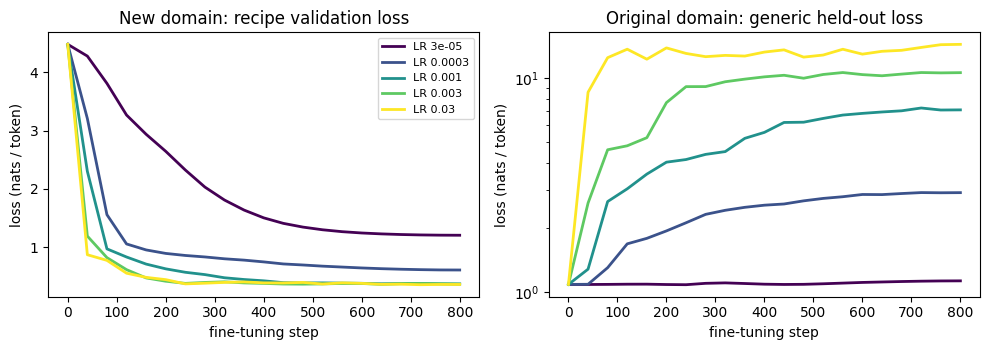

 peak LR  recipes val  generic held-out
   3e-05        1.206             1.131
  0.0003        0.610             2.916
   0.001        0.372             7.095
   0.003        0.368            10.583
    0.03        0.362            14.343


In [14]:
lr_values = [3e-5, 3e-4, 1e-3, 3e-3, 3e-2]
lr_results, lr_models = {}, {}
for lr in lr_values:
    m = copy.deepcopy(base)
    lr_results[lr] = finetune(m, rec_train, steps=FT_STEPS, lr=lr, eval_sets=eval_sets, eval_every=40)
    lr_models[lr] = m                       # reused in Section 9

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
cmap = plt.cm.viridis
for i, lr in enumerate(lr_values):
    h = lr_results[lr]
    for ax, key in zip(axes, ("recipes (val)", "generic (held out)")):
        ax.plot([x[0] for x in h], [x[2][key] for x in h], color=cmap(i / (len(lr_values) - 1)), lw=2, label=f"LR {lr:g}")
for ax, t in zip(axes, ("New domain: recipe validation loss", "Original domain: generic held-out loss")):
    ax.set_title(t); ax.set_xlabel("fine-tuning step"); ax.set_ylabel("loss (nats / token)")
axes[1].set_yscale("log"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'peak LR':>8} {'recipes val':>12} {'generic held-out':>17}")
for lr in lr_values:
    e = lr_results[lr][-1][2]; print(f"{lr:8g} {e['recipes (val)']:12.3f} {e['generic (held out)']:17.3f}")

**Reading the figure** (toy model, one run per setting, so treat trends, not exact numbers):

- **Too small (`3e-5`):** the recipe loss is still high after 800 steps, but the generic loss has barely changed. Little is learned and little is forgotten.
- **Moderate (`3e-4`):** the recipe loss falls well, and the generic loss rises noticeably.
- **`1e-3` and above:** the recipe loss has already flattened at about the same value (it cannot go much lower on this data), but the generic loss keeps climbing as the learning rate grows. The extra learning rate buys no recipe improvement and costs a lot of original ability, so the model has largely overwritten what it knew.
- The right setting depends on the goal: if only the recipe task matters, forgetting generic text may be acceptable; if the model must keep working as a general model, it is not. The **toy model has very little capacity**, so its forgetting is much more extreme than GPT-2's would be, but the direction of the trade-off is the same.
- Also notice that **validation loss, not training loss**, is what we chose by. On a real model the same sweep is expensive, which is why a small number of principled trials is typical.

### Mitigating forgetting

| Approach | Idea | Cost |
| --- | --- | --- |
| **Lower LR / fewer steps** | move the weights less | may under-fit the new task |
| **Replay (data mixing)** | include some original-style data in each batch | needs access to such data |
| **Freezing layers** | train only part of the network | keeps old knowledge but is partial fine-tuning; a precursor of PEFT |
| **Regularizing toward the pretrained weights** | penalize drift from $\theta_0$ (e.g. Kirkpatrick et al., 2017) | extra hyperparameters |

### Small data and overfitting

Fine-tuning sets are usually small. If you train for many epochs on a few hundred examples, the training loss keeps falling as the model memorizes them, while the validation loss stops improving and then rises. The **gap** between the two is the sign of overfitting. So:

- **Monitor validation loss and keep the best checkpoint**, or stop early, rather than training for a fixed number of epochs.
- With few examples, prefer a smaller learning rate and fewer epochs, and add more diverse data if you can.

## 8. A model that never stops: the end-of-text label

Every training document should end with the end-of-text token **with a real label**, so that the model learns to produce it, and generation can stop. A very common bug comes from padding. Real GPT-2 has no pad token, so people set `pad_token = eos_token` and then mask labels with a condition such as `labels[input_ids == pad_token_id] = -100`. That masks **every** end-of-text token, including the genuine ones that terminate each document.

The correct approach is to mask using the **attention mask** (which positions are real) rather than the token identity.

We reproduce the bug in the toy: the same fine-tuning, except `<eos>` labels are masked. Then we sample 40 completions at temperature 1 and count how many stop on their own within 30 new tokens.

In [15]:
def make_batch_eos_masked(docs):
    ids, labels = make_batch(docs)
    labels[ids == EOS] = -100            # BUG: removes the real end-of-text label along with the padding
    return ids, labels

@torch.no_grad()
def stop_rate(model, n=40, seed=0):
    g = torch.Generator().manual_seed(seed); stopped = 0; dishes = list(POOL)
    for i in range(n):
        text = generate(model, f"recipe : {dishes[i % len(dishes)]} ;", max_new_tokens=30, temperature=1.0, generator=g)
        stopped += text.endswith("<eos>")
    return stopped, n, text

for name, make in (("<eos> labelled (correct)", make_batch), ("<eos> masked (bug)", make_batch_eos_masked)):
    m = copy.deepcopy(base)
    finetune(m, rec_train, steps=FT_STEPS, lr=1e-3, make=make)
    s, n, last = stop_rate(m)
    print(f"{name:26} stopped on its own: {s:2d}/{n}")
    print("   last sample:", last, "\n")

<eos> labelled (correct)   stopped on its own: 40/40
   last sample: recipe : upma ; ingredients : onion , mustard , chili ; steps : roast , stir , serve <eos> 

<eos> masked (bug)         stopped on its own:  0/40
   last sample: recipe : upma ; ingredients : semolina , mustard , chili ; steps : roast , stir , serve ingredients : roast , stir , saute , stir , stir , serve , stir 



**Reading the output:** with the end-of-text label the model stops after the record in (nearly) every sample. When that label is masked, the model never receives a signal to end, so it runs on until the token limit and often starts a new, malformed record. Nothing in the loss curve would reveal this: the bug is only visible by generating.

> **Rule of thumb:** after building labels, *print one decoded example with its labels* and check the last real token. It takes ten seconds and catches this class of bug.

## 9. Evaluating a fine-tuned model

### What each measurement tells you

| Measurement | What it tells you | What it does **not** tell you |
| --- | --- | --- |
| **Validation loss / perplexity** | how well the model predicts held-out text from the same distribution | whether generated text is correct or useful; it is not comparable across tokenizers or datasets |
| **Held-out original-domain loss** | how much general ability was lost | whether the loss matters for your application |
| **Generations, same prompts and decoding settings** | what a user actually sees; format, style, stopping | statistical reliability from a handful of samples |
| **Task-specific automatic checks** | whether outputs satisfy rules you can write down | quality beyond those rules |
| **BLEU / ROUGE** (n-gram overlap with references) | surface overlap with a reference text | factuality or usefulness; depends on tokenization and on having good references |
| **Human review with a rubric** | usefulness, correctness, tone | cost and consistency; needs clear criteria and several raters |

Always compare the fine-tuned model with the **base model under identical prompts and decoding settings**; otherwise an improvement could come from a different prompt or temperature rather than from fine-tuning. Record those settings with the result.

### A rule-based check for the toy task

Because the toy recipes follow a known structure, we can *write down what a correct output is* and measure it automatically over many samples. For the base model and the models from the Section 7 learning-rate sweep, we draw 60 completions at temperature 1 (seeded) and classify them:

| Category | Meaning |
| --- | --- |
| **format-valid** | matches `recipe : D ; ingredients : a , b , c ; steps : x , y , z <eos>` |
| **content-valid** | format-valid, **and** the ingredients and steps are a possible recipe for dish `D` |
| **copied** | content-valid *and* identical to a recipe in the training set |
| **novel valid** | content-valid and not in the training set: a correct recipe the model was never shown |

“Copied” is a toy version of a real concern: fine-tuned models can **memorize and reproduce training examples**, which matters for private or copyrighted data.

In [ ]:
RECIPE_RE = re.compile(r"^recipe : (\w+) ; ingredients : (\w+) , (\w+) , (\w+) ; steps : (\w+) , (\w+) , (\w+) <eos>$")
VALID = {d: {(tuple(c), tuple(s)) for c in itertools.combinations(ings, 3) for s in itertools.combinations(steps, 3)}
         for d, (ings, steps) in POOL.items()}
TRAIN_SET = set(rec_train)

def score_samples(model, n=60, seed=0):
    g = torch.Generator().manual_seed(seed); dishes = list(POOL)
    counts = dict(format=0, content=0, copied=0, novel=0)
    for i in range(n):
        d = dishes[i % len(dishes)]
        text = generate(model, f"recipe : {d} ;", max_new_tokens=30, temperature=1.0, generator=g)
        m = RECIPE_RE.match(text)
        if not m: continue
        counts["format"] += 1
        dish, ing, steps = m.group(1), tuple(m.group(2, 3, 4)), tuple(m.group(5, 6, 7))
        if dish in VALID and (ing, steps) in VALID[dish]:
            counts["content"] += 1
            record = text.removesuffix(" <eos>")
            if record in TRAIN_SET: counts["copied"] += 1
            else: counts["novel"] += 1
    return {k: v / n for k, v in counts.items()}

candidates = {"base (no fine-tuning)": base}
for lr in (3e-5, 3e-4, 1e-3, 3e-3):
    candidates[f"fine-tuned, LR {lr:g}"] = lr_models[lr]           # the models trained in the Section 7 sweep

print(f"{'model':26} {'recipe loss':>11} {'generic loss':>12} {'format-valid':>13} {'content-valid':>14} {'copied':>7} {'novel valid':>12}")
for name, m in candidates.items():
    s = score_samples(m)
    print(f"{name:26} {evaluate(m, rec_val):11.3f} {evaluate(m, gen_val):12.3f} {s['format']:13.0%} {s['content']:14.0%} {s['copied']:7.0%} {s['novel']:12.0%}")

**Reading the table** (60 samples per model, one seed: percentages move by several points with another seed, so look at the large differences only)

- The base model almost never produces a correctly formatted recipe, and the smallest learning rate barely changes that.
- As the learning rate grows, format-validity rises to near 100%. Content-validity is **lower** than format-validity at every setting: some recipes *look* right but combine ingredients or steps that do not belong to the dish. A loss value would not show this.
- The two largest learning rates reach almost the same recipe loss, yet their content-validity differs clearly. The generic loss differs a lot too. **Validation loss alone does not rank these models.**
- “Copied” counts valid outputs that are verbatim training records. The training set holds about half of all 240 possible recipes, so a model that sampled uniformly from every valid recipe would copy about half the time. Here most valid outputs are copies, and almost none are novel valid recipes, so the model has largely **memorized its training records** rather than composing new valid ones. For real data you would look for long exact matches or n-gram overlap with the training set, which matters most for private or copyrighted data.
- This check works only because we can write the rules down. For real recipes you would need human review against a rubric (is it safe, complete, correctly ordered?), which BLEU or ROUGE cannot replace.

## 10. Responsible use

- **Data rights and privacy.** Fine-tune only on data you are allowed to use. Fine-tuned models can memorize and later reproduce training examples, including personal or confidential text. Use public, appropriately licensed data or clearly labeled synthetic examples, and do not put sensitive records in prompts, logs, or datasets.
- **Inherited and amplified bias.** GPT-2 reflects its web-scale training text, and a small fine-tuning set can sharpen those tendencies or add its own. Check outputs across the kinds of inputs your users will provide, not only on average loss.
- **Fluency is not truth.** The model learns what text tends to follow a prefix. A well-formatted recipe can contain unsafe or wrong instructions (Section 9). Keep a human in the loop for anything consequential.
- **Teaching prototype, not a product.** The models in this note are for learning. Deploying one would need evaluation on realistic data, monitoring, and review of license terms for both the base model and the fine-tuning data.

## 11. Check your understanding

1. What is the same and what is different between the pretraining objective and the fine-tuning objective? Why must the learning rate usually be smaller in fine-tuning?
2. For `tokens = [A, B, C, D]` with `labels` equal to the tokens except `-100` on `A` and `B`, list which predictions contribute to the loss and what the denominator of the mean is.
3. Why is `labels[input_ids == pad_token_id] = -100` dangerous when `pad_token = eos_token`? What would you use instead, and how would you notice the bug?
4. Hugging Face's `GPT2LMHeadModel` shifts labels internally. What goes wrong if you also shift them before passing them in?
5. Estimate the fp32 training-state memory for a 355M-parameter model (weights, gradients, Adam moments). Which part would a mixed-precision setup *not* shrink, and why?
6. Sketch the validation loss curve for a run with too small a dataset and too many epochs. Which checkpoint would you keep?
7. In Section 7, the largest learning rate gave the lowest recipe loss. Argue for and against choosing it.
8. A colleague reports that fine-tuning “improved ROUGE by 3 points”. List three controls you would ask about before believing it helps users.
9. Give one case where fine-tuning is the better tool than retrieval, and one where retrieval is better.

**Next:** [Fine-tuning with the Hugging Face `Trainer`](hf_trainer_fine_tuning.ipynb) runs the same kind of loop through the `Trainer` API on a real pretrained model.

**Further reading**

- Radford et al. (2019), [*Language Models are Unsupervised Multitask Learners*](https://cdn.openai.com/better-language-models/language-models.pdf): the GPT-2 report.
- Howard & Ruder (2018), [*Universal Language Model Fine-tuning for Text Classification*](https://arxiv.org/abs/1801.06146): early evidence that gradual adaptation of a pretrained language model works, with learning-rate schedules designed for it.
- Loshchilov & Hutter (2019), [*Decoupled Weight Decay Regularization*](https://arxiv.org/abs/1711.05101): AdamW.
- Kirkpatrick et al. (2017), [*Overcoming catastrophic forgetting in neural networks*](https://arxiv.org/abs/1612.00796): a regularization approach to forgetting.
- Carlini et al. (2021), [*Extracting Training Data from Large Language Models*](https://arxiv.org/abs/2012.07805): memorization and privacy.
- Hugging Face: [causal language modeling task guide](https://huggingface.co/docs/transformers/tasks/language_modeling) · [GPT-2 model card](https://huggingface.co/openai-community/gpt2) · [Trainer documentation](https://huggingface.co/docs/transformers/main_classes/trainer).